# Regression Metrics: Complete Guide

This notebook covers the most important regression evaluation metrics:
- **MAE** (Mean Absolute Error)
- **MSE** (Mean Squared Error)
- **RMSE** (Root Mean Squared Error)
- **R² Score** (Coefficient of Determination)
- **Adjusted R² Score**

Each metric includes:
- Mathematical formula
- Intuitive explanation
- Implementation from scratch
- Scikit-learn implementation
- Practical example with comments

## Setup and Imports

In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.datasets import make_regression
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
np.random.seed(42)

# Plotting style
plt.style.use('seaborn-v0_8-darkgrid')
%matplotlib inline

## 1. Mean Absolute Error (MAE)

### Definition
MAE measures the average absolute difference between predicted and actual values.

### Formula
$$MAE = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$$

where:
- $y_i$ = actual value
- $\hat{y}_i$ = predicted value
- $n$ = number of samples

### Interpretation
- **Range**: [0, ∞)
- **Lower is better**
- Unit: Same as the target variable
- **Pros**: Easy to interpret, robust to outliers
- **Cons**: Not differentiable at zero, doesn't penalize large errors heavily

Actual values: [100 150 200 250 300 350 400 450 500]
Predicted values: [110 140 190 260 290 360 410 440 490]

Errors (Actual - Predicted): [-10  10  10 -10  10 -10 -10  10  10]
Absolute Errors: [10 10 10 10 10 10 10 10 10]
Squared Errors: [100 100 100 100 100 100 100 100 100]

MAE (Manual calculation): 10.0000
MAE (Scikit-learn): 10.0000


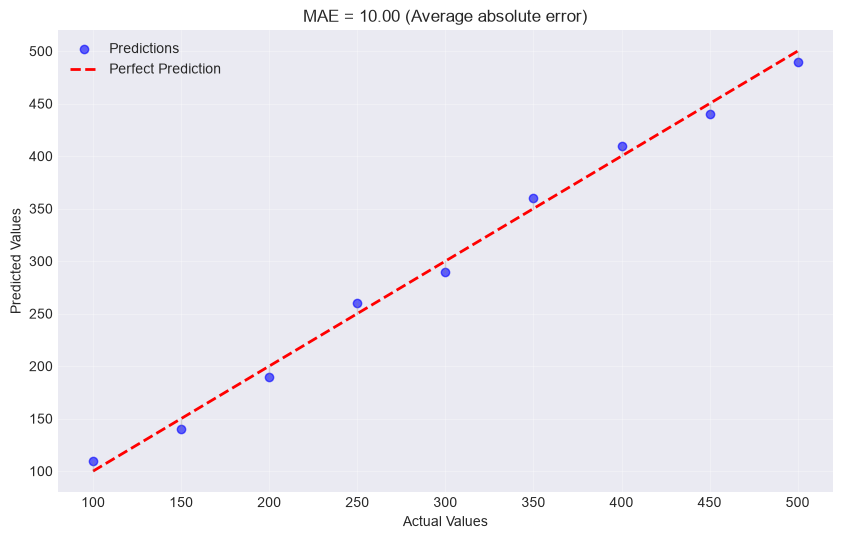

In [75]:
# Example data: Actual vs Predicted values
y_actual = np.array([100, 150, 200, 250, 300, 350, 400, 450, 500])
y_pred = np.array([110, 140, 190, 260, 290, 360, 410, 440, 490])

print("Actual values:", y_actual)
print("Predicted values:", y_pred)
print()

# Calculate errors
errors = y_actual - y_pred
absolute_errors = np.abs(errors)
squared_errors = errors ** 2

print("Errors (Actual - Predicted):", errors)
print("Absolute Errors:", absolute_errors)
print("Squared Errors:", squared_errors)
print()

# MAE from scratch
mae_manual = np.mean(absolute_errors)
print(f"MAE (Manual calculation): {mae_manual:.4f}")

# MAE using scikit-learn
mae_sklearn = mean_absolute_error(y_actual, y_pred)
print(f"MAE (Scikit-learn): {mae_sklearn:.4f}")

# Visual interpretation
plt.figure(figsize=(10, 6))
plt.scatter(y_actual, y_pred, color='blue', alpha=0.6, label='Predictions')
plt.plot([y_actual.min(), y_actual.max()], [y_actual.min(), y_actual.max()], 
         'r--', linewidth=2, label='Perfect Prediction')

# Add error lines
for i in range(len(y_actual)):
    plt.plot([y_actual[i], y_actual[i]], [y_actual[i], y_pred[i]], 
             'gray', alpha=0.3, linewidth=1)

plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title(f'MAE = {mae_manual:.2f} (Average absolute error)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### When to Use MAE?
- When you want errors in the same unit as the target variable
- When outliers are present (robust to outliers)
- When you want a simple, interpretable metric

## 2. Mean Squared Error (MSE)

### Definition
MSE measures the average squared difference between predicted and actual values.

### Formula
$$MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

### Interpretation
- **Range**: [0, ∞)
- **Lower is better**
- Unit: Squared unit of target variable
- **Pros**: Differentiable, heavily penalizes large errors
- **Cons**: Sensitive to outliers, not in original units

In [68]:
# Using the same example data
print("Actual values:", y_actual)
print("Predicted values:", y_pred)
print()

# MSE from scratch
mse_manual = np.mean(squared_errors)
print(f"MSE (Manual calculation): {mse_manual:.4f}")

# MSE using scikit-learn
mse_sklearn = mean_squared_error(y_actual, y_pred)
print(f"MSE (Scikit-learn): {mse_sklearn:.4f}")
print()

# Demonstrate the effect of squaring errors
print("Effect of squaring errors:")
print(f"Largest absolute error: {np.max(absolute_errors):.2f}")
print(f"Largest squared error: {np.max(squared_errors):.2f}")
print(f"Sum of absolute errors: {np.sum(absolute_errors):.2f}")
print(f"Sum of squared errors: {np.sum(squared_errors):.2f}")


Actual values: [100 150 200 250 300 350 400 450 500]
Predicted values: [110 140 190 260 290 360 410 440 490]

MSE (Manual calculation): 100.0000
MSE (Scikit-learn): 100.0000

Effect of squaring errors:
Largest absolute error: 10.00
Largest squared error: 100.00
Sum of absolute errors: 90.00
Sum of squared errors: 900.00


### When to Use MSE?
- When large errors are particularly undesirable
- When you need a differentiable loss function (e.g., for gradient descent)
- When errors follow a normal distribution

## 3. Root Mean Squared Error (RMSE)

### Definition
RMSE is the square root of MSE, bringing the error back to the original units.

### Formula
$$RMSE = \sqrt{MSE} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2}$$

### Interpretation
- **Range**: [0, ∞)
- **Lower is better**
- Unit: Same as target variable
- **Pros**: In original units, penalizes large errors
- **Cons**: Sensitive to outliers

In [69]:
# RMSE from scratch
rmse_manual = np.sqrt(mse_manual)
print(f"RMSE (Manual calculation): {rmse_manual:.4f}")

# RMSE using scikit-learn (sqrt of MSE)
rmse_sklearn = np.sqrt(mean_squared_error(y_actual, y_pred))
print(f"RMSE (Scikit-learn): {rmse_sklearn:.4f}")
print()

# Compare MAE vs RMSE
print("Comparison:")
print(f"MAE:  {mae_manual:.4f}")
print(f"RMSE: {rmse_manual:.4f}")
print(f"Difference: {rmse_manual - mae_manual:.4f}")
print("\nRMSE > MAE because RMSE penalizes larger errors more heavily.")

RMSE (Manual calculation): 10.0000
RMSE (Scikit-learn): 10.0000

Comparison:
MAE:  10.0000
RMSE: 10.0000
Difference: 0.0000

RMSE > MAE because RMSE penalizes larger errors more heavily.


### When to Use RMSE?
- When you want errors in original units but still penalize large errors
- When the cost of large errors is disproportionately high
- As a standard metric for many regression problems

## 4. R² Score (Coefficient of Determination)

### Definition
R² measures the proportion of variance in the dependent variable that is predictable from the independent variables.

### Formula
$$R^2 = 1 - \frac{SS_{res}}{SS_{tot}}$$

where:
- $SS_{res} = \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$ (Sum of Squared Residuals)
- $SS_{tot} = \sum_{i=1}^{n} (y_i - \bar{y})^2$ (Total Sum of Squares)
- $\bar{y}$ = mean of actual values

### Interpretation
- **Range**: (-∞, 1]
- **Higher is better** (1 = perfect prediction, 0 = baseline model)
- **Can be negative** if the model performs worse than predicting the mean
- **Pros**: Interpretable as percentage of variance explained
- **Cons**: Can be misleading for non-linear models, always increases with more features

In [70]:
# Calculate R² from scratch
# Using the same example data
mean_actual = np.mean(y_actual)
ss_res = np.sum((y_actual - y_pred) ** 2)  # Sum of squared residuals
ss_tot = np.sum((y_actual - mean_actual) ** 2)  # Total sum of squares

r2_manual = 1 - (ss_res / ss_tot)

print(f"Mean of actual values: {mean_actual:.2f}")
print(f"SS_res (Sum of Squared Residuals): {ss_res:.2f}")
print(f"SS_tot (Total Sum of Squares): {ss_tot:.2f}")
print(f"R² (Manual calculation): {r2_manual:.4f}")

# R² using scikit-learn
r2_sklearn = r2_score(y_actual, y_pred)
print(f"R² (Scikit-learn): {r2_sklearn:.4f}")
print()

# Interpretation
print(f"Interpretation: {r2_manual*100:.1f}% of the variance in the target variable is explained by the model.")
print(f"Residual variance: {(1 - r2_manual)*100:.1f}% remains unexplained.")

Mean of actual values: 300.00
SS_res (Sum of Squared Residuals): 900.00
SS_tot (Total Sum of Squares): 150000.00
R² (Manual calculation): 0.9940
R² (Scikit-learn): 0.9940

Interpretation: 99.4% of the variance in the target variable is explained by the model.
Residual variance: 0.6% remains unexplained.


### When to Use R²?
- To understand the proportion of variance explained
- For model comparison (on the same dataset)
- To communicate model performance to non-technical stakeholders

## 5. Adjusted R² Score

### Definition
Adjusted R² is a modified version of R² that adjusts for the number of predictors in the model.

### Formula
$$R^2_{adj} = 1 - (1 - R^2) \frac{n-1}{n-p-1}$$

where:
- $n$ = number of samples
- $p$ = number of predictors (features)
- $R^2$ = regular R² score

### Interpretation
- **Range**: (-∞, 1]
- **Higher is better**
- **Penalizes adding irrelevant features**
- **Pros**: Prevents overfitting, better for model comparison
- **Cons**: Can be misleading for small sample sizes

In [71]:
y_actual = np.array([100, 150, 200, 250, 300, 350, 400, 450, 500])
y_pred = np.array([110, 140, 190, 260, 290, 360, 410, 440, 490])

# 1. Mean of actual values
y_mean = np.mean(y_actual)  # 300.0

# 2. Sum of Squared Residuals (SS_res) and Total Sum of Squares (SS_tot)
ss_res = np.sum((y_actual - y_pred) ** 2)  # 900
ss_tot = np.sum((y_actual - y_mean) ** 2)  # 150000

# 3. R-squared
r2 = 1 - (ss_res / ss_tot)  # 0.994

# 4. Adjusted R-squared
n = len(y_actual)  # 9
p = 1  # 1 predictor
adj_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))

print("Adjusted R2:",adj_r2)


Adjusted R2: 0.9931428571428571


### When to Use Adjusted R²?
- When comparing models with different numbers of features
- To prevent overfitting by discouraging inclusion of irrelevant features
- For feature selection purposes

## 6. Complete Example: House Price Prediction

Let's put all metrics together in a complete regression example.

In [72]:
# Generate a more realistic dataset
np.random.seed(42)

# Create synthetic house price data
n_samples = 500

# Features: size_sqft, bedrooms, bathrooms, age, proximity_to_city
size_sqft = np.random.normal(1500, 500, n_samples).clip(500, 4000)
bedrooms = np.random.randint(1, 6, n_samples)
bathrooms = np.random.randint(1, 4, n_samples)
age = np.random.normal(15, 10, n_samples).clip(0, 50)
proximity = np.random.normal(10, 5, n_samples).clip(1, 25)

# Generate house prices with some noise
price = (100 * size_sqft + 
         50000 * bedrooms + 
         30000 * bathrooms - 
         5000 * age - 
         10000 * proximity + 
         np.random.normal(0, 50000, n_samples))

# Create DataFrame
data = pd.DataFrame({
    'size_sqft': size_sqft,
    'bedrooms': bedrooms,
    'bathrooms': bathrooms,
    'age': age,
    'proximity': proximity,
    'price': price
})

print("House Price Dataset:")
print(data.head())
print()
print("Dataset shape:", data.shape)
print()

# Split into features and target
X = data.drop('price', axis=1)
y = data['price']

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# Calculate all metrics for training and testing
def calculate_all_metrics(y_true, y_pred, X):
    """Calculate all regression metrics including adjusted R²"""
    n = len(y_true)
    p = X.shape[1]
    
    metrics = {
        'MAE': mean_absolute_error(y_true, y_pred),
        'MSE': mean_squared_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R²': r2_score(y_true, y_pred),
        'Adjusted R²': adjusted_r2_score(y_true, y_pred, n, p)
    }
    return metrics

# Calculate metrics
train_metrics = calculate_all_metrics(y_train, y_train_pred, X_train)
test_metrics = calculate_all_metrics(y_test, y_test_pred, X_test)

# Display results
metrics_df = pd.DataFrame({
    'Metric': list(train_metrics.keys()),
    'Training': list(train_metrics.values()),
    'Testing': list(test_metrics.values())
})

print("=== Model Performance Metrics ===")
print(metrics_df.to_string(index=False))
print()

# Interpretation
print("=== Interpretation ===")
print(f"Average prediction error (MAE): ${train_metrics['MAE']:,.2f}")
print(f"Model explains {train_metrics['R²']*100:.1f}% of variance in house prices")
print(f"Adjusted R²: {train_metrics['Adjusted R²']:.4f} (penalizes for 5 features)")
print()

# Check for overfitting
r2_diff = train_metrics['R²'] - test_metrics['R²']
print(f"R² difference (Train - Test): {r2_diff:.4f}")
if r2_diff > 0.1:
    print("Warning: Possible overfitting detected!")
else:
    print("Good: Model generalizes well to new data.")

House Price Dataset:
     size_sqft  bedrooms  bathrooms        age  proximity          price
0  1748.357077         2          2  13.365327   4.684455  254116.093762
1  1430.867849         2          2   3.548226  10.690436  164665.783963
2  1823.844269         3          1  20.877630   8.707996  216617.411612
3  2261.514928         3          3  16.151518  14.633605  191635.609343
4  1382.923313         5          3   7.579803  12.436799  386619.154127

Dataset shape: (500, 6)

=== Model Performance Metrics ===
     Metric     Training      Testing
        MAE 4.200397e+04 3.755253e+04
        MSE 2.843928e+09 2.186170e+09
       RMSE 5.332849e+04 4.675649e+04
         R² 8.161611e-01 8.672712e-01
Adjusted R² 8.138281e-01 8.602112e-01

=== Interpretation ===
Average prediction error (MAE): $42,003.97
Model explains 81.6% of variance in house prices
Adjusted R²: 0.8138 (penalizes for 5 features)

R² difference (Train - Test): -0.0511
Good: Model generalizes well to new data.


## 7. Visualization of Results

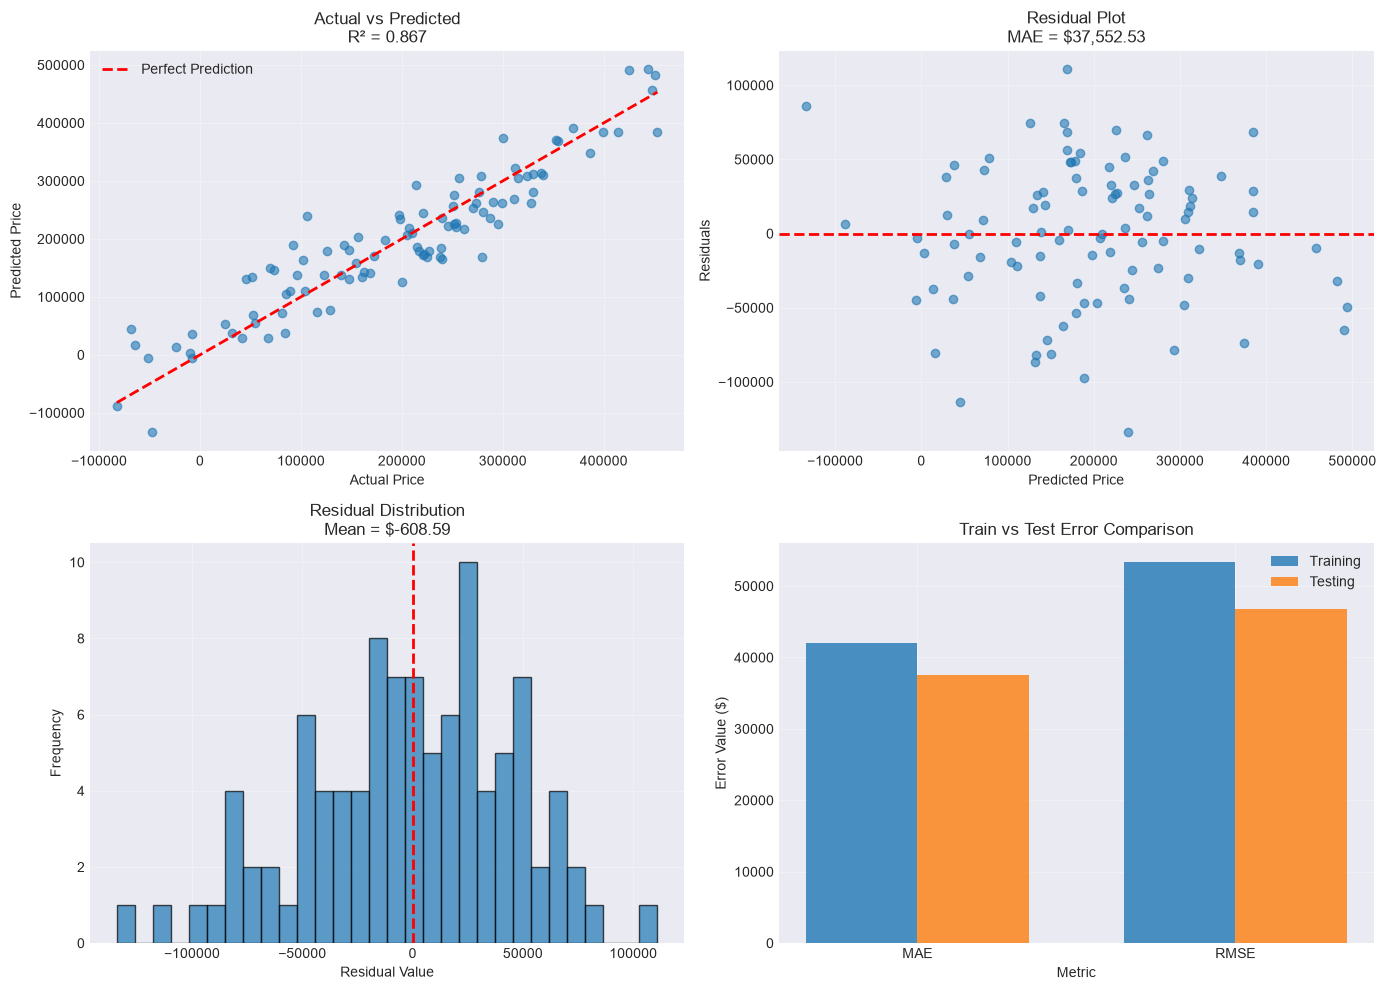

In [73]:
# Create comprehensive visualization
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Actual vs Predicted (Test set)
ax1 = axes[0, 0]
ax1.scatter(y_test, y_test_pred, alpha=0.6)
ax1.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 
         'r--', linewidth=2, label='Perfect Prediction')
ax1.set_xlabel('Actual Price')
ax1.set_ylabel('Predicted Price')
ax1.set_title(f'Actual vs Predicted\nR² = {test_metrics["R²"]:.3f}')
ax1.legend()
ax1.grid(True, alpha=0.3)

# 2. Residuals
ax2 = axes[0, 1]
residuals = y_test - y_test_pred
ax2.scatter(y_test_pred, residuals, alpha=0.6)
ax2.axhline(y=0, color='red', linestyle='--', linewidth=2)
ax2.set_xlabel('Predicted Price')
ax2.set_ylabel('Residuals')
ax2.set_title(f'Residual Plot\nMAE = ${test_metrics["MAE"]:,.2f}')
ax2.grid(True, alpha=0.3)

# 3. Residual Distribution
ax3 = axes[1, 0]
ax3.hist(residuals, bins=30, edgecolor='black', alpha=0.7)
ax3.axvline(x=0, color='red', linestyle='--', linewidth=2)
ax3.set_xlabel('Residual Value')
ax3.set_ylabel('Frequency')
ax3.set_title(f'Residual Distribution\nMean = ${np.mean(residuals):.2f}')
ax3.grid(True, alpha=0.3)

# 4. Metrics Comparison
ax4 = axes[1, 1]
metric_names = ['MAE', 'RMSE']
train_values = [train_metrics['MAE'], train_metrics['RMSE']]
test_values = [test_metrics['MAE'], test_metrics['RMSE']]

x = np.arange(len(metric_names))
width = 0.35
ax4.bar(x - width/2, train_values, width, label='Training', alpha=0.8)
ax4.bar(x + width/2, test_values, width, label='Testing', alpha=0.8)
ax4.set_xlabel('Metric')
ax4.set_ylabel('Error Value ($)')
ax4.set_title('Train vs Test Error Comparison')
ax4.set_xticks(x)
ax4.set_xticklabels(metric_names)
ax4.legend()
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Comparison Table: All Metrics

In [74]:
# Create a comprehensive comparison table
comparison_data = {
    'Metric': ['MAE', 'MSE', 'RMSE', 'R²', 'Adjusted R²'],
    'Formula': [
        '$\\frac{1}{n}\\sum|y_i-\\hat{y}_i|$',
        '$\\frac{1}{n}\\sum(y_i-\\hat{y}_i)^2$',
        '$\\sqrt{\\frac{1}{n}\\sum(y_i-\\hat{y}_i)^2}$',
        '$1-\\frac{SS_{res}}{SS_{tot}}$',
        '$1-(1-R^2)\\frac{n-1}{n-p-1}$'
    ],
    'Range': [
        '[0, ∞)',
        '[0, ∞)',
        '[0, ∞)',
        '(-∞, 1]',
        '(-∞, 1]'
    ],
    'Unit': [
        'Same as target',
        'Squared target',
        'Same as target',
        'Proportion',
        'Proportion'
    ],
    'Sensitive to Outliers': [
        'Low',
        'High',
        'High',
        'High',
        'High'
    ],
    'Interpretation': [
        'Average absolute error',
        'Average squared error',
        'Root of average squared error',
        'Variance explained',
        'Variance explained (penalized)'
    ]
}

comparison_df = pd.DataFrame(comparison_data)
print("=== Regression Metrics Comparison Table ===")
print(comparison_df.to_string(index=False))
print()

print("=== Quick Selection Guide ===")
print("🔹 Use MAE when:")
print("   - You need intuitive interpretation")
print("   - Outliers are present")
print("   - Errors should be in original units")
print()
print("🔹 Use MSE when:")
print("   - Large errors must be penalized heavily")
print("   - You need a differentiable loss function")
print()
print("🔹 Use RMSE when:")
print("   - You want errors in original units")
print("   - Large errors are undesirable")
print()
print("🔹 Use R² when:")
print("   - You want to explain variance")
print("   - Comparing models on same dataset")
print()
print("🔹 Use Adjusted R² when:")
print("   - Comparing models with different numbers of features")
print("   - Performing feature selection")
print("   - Preventing overfitting")

=== Regression Metrics Comparison Table ===
     Metric                                   Formula   Range           Unit Sensitive to Outliers                 Interpretation
        MAE          $\frac{1}{n}\sum|y_i-\hat{y}_i|$  [0, ∞) Same as target                   Low         Average absolute error
        MSE        $\frac{1}{n}\sum(y_i-\hat{y}_i)^2$  [0, ∞) Squared target                  High          Average squared error
       RMSE $\sqrt{\frac{1}{n}\sum(y_i-\hat{y}_i)^2}$  [0, ∞) Same as target                  High  Root of average squared error
         R²             $1-\frac{SS_{res}}{SS_{tot}}$ (-∞, 1]     Proportion                  High             Variance explained
Adjusted R²              $1-(1-R^2)\frac{n-1}{n-p-1}$ (-∞, 1]     Proportion                  High Variance explained (penalized)

=== Quick Selection Guide ===
🔹 Use MAE when:
   - You need intuitive interpretation
   - Outliers are present
   - Errors should be in original units

🔹 Use MSE when:
   - La

## Summary

### Key Takeaways:

1. **MAE**: Simple, robust, easy to interpret, insensitive to outliers
2. **MSE**: Penalizes large errors, differentiable, sensitive to outliers
3. **RMSE**: Same as MSE but in original units, sensitive to outliers
4. **R²**: Percentage of variance explained, always increases with more features
5. **Adjusted R²**: Penalizes adding irrelevant features, better for model comparison

### Choosing the Right Metric:

| Scenario | Recommended Metric |
|----------|-------------------|
| Business reporting | MAE (interpretable) |
| Large errors are costly | RMSE or MSE |
| Model comparison with same features | R² |
| Model comparison with different features | Adjusted R² |
| Feature selection | Adjusted R² |
| Gradient-based optimization | MSE |

### Best Practice:
Use **multiple metrics** to get a complete picture of model performance:
- MAE for average error interpretation
- RMSE for penalizing large errors
- R²/Adjusted R² for variance explanation
- Always validate on test data to check for overfitting